# Rice Disease Image Classifier: MobileNetV3 + CBAM

**Capstone Project - AgriBot Image Classification Module**

This notebook trains a lightweight, production-ready rice disease classifier using:
- **MobileNetV3-Large** backbone (ImageNet pretrained)
- **CBAM (Convolutional Block Attention Module)** for improved attention
- **ONNX export** for CPU-bound inference in AgriBot

## Deliverables
1. Best PyTorch checkpoint (`.pt`)
2. ONNX model (`.onnx`)
3. Labels file (`labels.txt`)
4. Model Card with metrics and usage guidelines


---
## 1. Setup and Reproducibility


In [1]:
# ===== CONFIGURATION =====
# Set DATA_DIR to your rice disease dataset (ImageFolder structure).
# Expected structure:
#   DATA_DIR/
#       train/
#           class1/
#           class2/
#           ...
#       val/  (optional - will split from train if missing)
#       test/ (optional - will split from train if missing)
#
# Common datasets: Rice Leaf Disease Dataset from Kaggle, PlantVillage Rice subset

DATA_DIR = r"/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG"  # <-- UPDATE THIS PATH

# Model configuration
USE_CBAM = True           # Toggle to False for ablation study (MobileNetV3 only)
MODEL_NAME = "mobilenetv3_large"  # "mobilenetv3_large" or "mobilenetv3_small"
NUM_EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 7
IMG_SIZE = 224

# Output paths
OUTPUT_DIR = "./outputs"
CHECKPOINT_PATH = f"{OUTPUT_DIR}/rice_disease_best.pt"
ONNX_PATH = f"{OUTPUT_DIR}/rice_disease_mobilenetv3_cbam.onnx" if USE_CBAM else f"{OUTPUT_DIR}/rice_disease_mobilenetv3.onnx"
LABELS_PATH = f"{OUTPUT_DIR}/labels.txt"

# Random seed for reproducibility
SEED = 42


In [2]:
# ===== IMPORTS AND SEED SETTING =====
import os
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

import torchvision
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, accuracy_score, top_k_accuracy_score
)

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

# Set seeds for reproducibility
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Print versions for reproducibility
print("\n=== Library Versions ===")
print(f"Python: {__import__('sys').version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
try:
    import onnxruntime as ort
    print(f"ONNX Runtime: {ort.__version__}")
except ImportError:
    print("ONNX Runtime: Not installed (install with: pip install onnxruntime)")
try:
    import onnxscript
    print(f"onnxscript: {onnxscript.__version__}")
except ImportError:
    print("onnxscript: Not installed (REQUIRED for ONNX export - install with: pip install onnxscript)")


Using device: cuda

=== Library Versions ===
Python: 3.12.12
PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
ONNX Runtime: Not installed (install with: pip install onnxruntime)
onnxscript: Not installed (REQUIRED for ONNX export - install with: pip install onnxscript)


---
## 2. Data

### Data Loading and Preprocessing

We use standard ImageNet normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) 
since MobileNetV3 was pretrained on ImageNet.

**Data Augmentation** (train only):
- Random horizontal flip
- Random rotation (±15°)
- Color jitter (brightness, contrast)
- Random resized crop


In [3]:
# ===== DATA TRANSFORMS =====
# ImageNet normalization stats
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


In [4]:
# ===== LOAD DATASET =====
data_path = Path(DATA_DIR)

# Check if pre-split directories exist
train_dir = data_path / "train"
val_dir = data_path / "val" 
test_dir = data_path / "test"

if train_dir.exists() and val_dir.exists() and test_dir.exists():
    # Use pre-existing splits
    print("Using pre-existing train/val/test splits")
    train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
    val_dataset = datasets.ImageFolder(val_dir, transform=val_test_transform)
    test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform)
    class_names = train_dataset.classes
    
elif train_dir.exists():
    # Only train exists - create splits
    print("Creating train/val/test splits from train directory")
    full_dataset = datasets.ImageFolder(train_dir, transform=None)
    class_names = full_dataset.classes
    
    # Stratified split: 70% train, 15% val, 15% test
    targets = [s[1] for s in full_dataset.samples]
    
    train_idx, temp_idx = train_test_split(
        range(len(full_dataset)), test_size=0.3, 
        stratify=targets, random_state=SEED
    )
    temp_targets = [targets[i] for i in temp_idx]
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.5,
        stratify=temp_targets, random_state=SEED
    )
    
    # Create subsets with appropriate transforms
    train_dataset = Subset(datasets.ImageFolder(train_dir, transform=train_transform), train_idx)
    val_dataset = Subset(datasets.ImageFolder(train_dir, transform=val_test_transform), val_idx)
    test_dataset = Subset(datasets.ImageFolder(train_dir, transform=val_test_transform), test_idx)
    
else:
    # Flat directory structure - all classes in DATA_DIR
    print("Creating train/val/test splits from flat directory structure")
    full_dataset = datasets.ImageFolder(data_path, transform=None)
    class_names = full_dataset.classes
    
    targets = [s[1] for s in full_dataset.samples]
    
    train_idx, temp_idx = train_test_split(
        range(len(full_dataset)), test_size=0.3,
        stratify=targets, random_state=SEED
    )
    temp_targets = [targets[i] for i in temp_idx]
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.5,
        stratify=temp_targets, random_state=SEED
    )
    
    train_dataset = Subset(datasets.ImageFolder(data_path, transform=train_transform), train_idx)
    val_dataset = Subset(datasets.ImageFolder(data_path, transform=val_test_transform), val_idx)
    test_dataset = Subset(datasets.ImageFolder(data_path, transform=val_test_transform), test_idx)

num_classes = len(class_names)

print("\n=== Dataset Summary ===")
print(f"Number of classes: {num_classes}")
print(f"Class names: {class_names}")
print(f"Train samples: {len(train_dataset)}")
print(f"Val samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

# Check for 'healthy' class
has_healthy = any('healthy' in c.lower() for c in class_names)
if has_healthy:
    print("\n✓ 'Healthy' class detected - model can distinguish healthy vs diseased plants")
else:
    print("\n⚠ WARNING: No 'Healthy' class detected.")
    print("  Limitation: Model cannot identify healthy plants.")
    print("  Inference policy: Use confidence threshold; low-confidence predictions")
    print("  should trigger 'Unknown/Needs Expert Review' response.")


Creating train/val/test splits from flat directory structure

=== Dataset Summary ===
Number of classes: 6
Class names: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Train samples: 2680
Val samples: 574
Test samples: 575

✓ 'Healthy' class detected - model can distinguish healthy vs diseased plants


In [5]:
# ===== COMPUTE CLASS WEIGHTS FOR IMBALANCE HANDLING =====
"""
We use WeightedRandomSampler to handle class imbalance.

Justification: WeightedRandomSampler ensures each batch has approximately 
balanced class representation during training, which is more effective than 
loss-based class weights for moderately imbalanced datasets. This approach:
- Provides consistent gradient signals across classes
- Prevents majority class from dominating early training
- Works well with standard CrossEntropyLoss
"""

# Get training labels
if isinstance(train_dataset, Subset):
    train_labels = [train_dataset.dataset.targets[i] for i in train_dataset.indices]
else:
    train_labels = train_dataset.targets

# Compute class counts and weights
class_counts = Counter(train_labels)
print("\n=== Class Distribution (Training) ===")
for cls_idx, count in sorted(class_counts.items()):
    print(f"  {class_names[cls_idx]}: {count} samples")

# Calculate sample weights for WeightedRandomSampler
class_weights = {cls: 1.0 / count for cls, count in class_counts.items()}
sample_weights = [class_weights[label] for label in train_labels]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Create data loaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, 
    sampler=sampler, num_workers=4, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, 
    shuffle=False, num_workers=4, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, 
    shuffle=False, num_workers=4, pin_memory=True
)

print(f"\nData loaders created (batch_size={BATCH_SIZE})")



=== Class Distribution (Training) ===
  Bacterial Leaf Blight: 445 samples
  Brown Spot: 452 samples
  Healthy Rice Leaf: 457 samples
  Leaf Blast: 444 samples
  Leaf scald: 440 samples
  Sheath Blight: 442 samples

Data loaders created (batch_size=32)


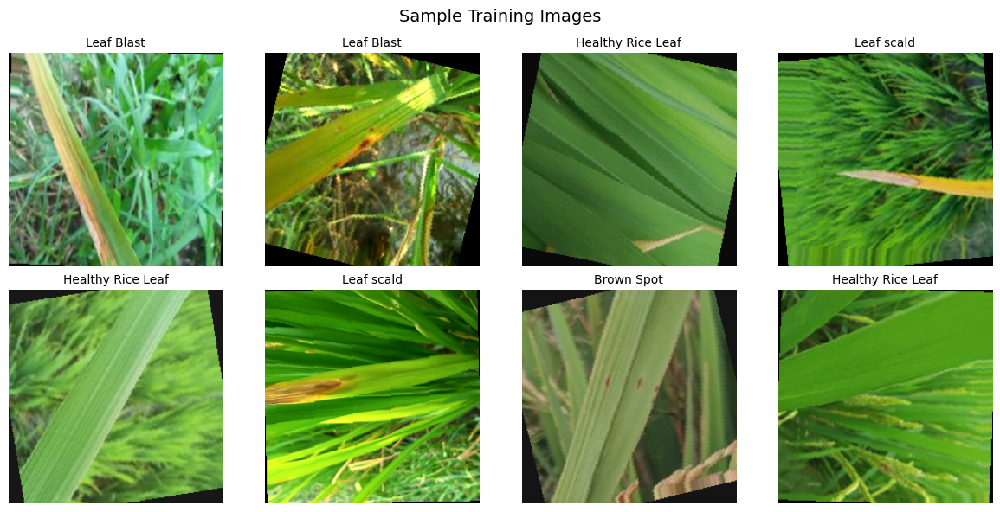

In [6]:
# ===== VISUALIZE SAMPLE IMAGES =====
def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Denormalize a tensor for visualization."""
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

# Get a batch
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        img = denormalize(images[i]).permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        ax.imshow(img)
        ax.set_title(class_names[labels[i]], fontsize=10)
    ax.axis('off')
plt.suptitle("Sample Training Images", fontsize=14)
plt.tight_layout()
plt.show()


---
## 3. Model (MobileNetV3 + CBAM)

### CBAM: Convolutional Block Attention Module

CBAM sequentially applies **channel attention** and **spatial attention** to refine features:

1. **Channel Attention**: Focuses on "what" features are important by computing 
   channel-wise statistics (max and average pooling) and passing through MLPs.

2. **Spatial Attention**: Focuses on "where" features are important by analyzing 
   spatial locations across channels.

**Integration Strategy**: We inject CBAM blocks at the end of selected InvertedResidual 
stages in MobileNetV3. Specifically, we add CBAM after layers 4, 7, 11, and 15 
(end of each major stage) to keep the model lightweight while capturing multi-scale attention.


In [7]:
# ===== CBAM MODULES =====

class ChannelAttention(nn.Module):
    """Channel attention module using average and max pooling."""
    
    def __init__(self, in_channels: int, reduction_ratio: int = 16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        # AdaptiveMaxPool2d is replaced by torch.amax in forward for ONNX compatibility
        
        # Shared MLP
        reduced_channels = max(in_channels // reduction_ratio, 8)
        self.mlp = nn.Sequential(
            nn.Conv2d(in_channels, reduced_channels, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced_channels, in_channels, 1, bias=False)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(torch.amax(x, dim=(2, 3), keepdim=True))
        attention = torch.sigmoid(avg_out + max_out)
        return x * attention


class SpatialAttention(nn.Module):
    """Spatial attention module using channel-wise pooling."""
    
    def __init__(self, kernel_size: int = 7):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=padding, bias=False)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = x.mean(dim=1, keepdim=True)
        max_out = x.max(dim=1, keepdim=True)[0]
        concat = torch.cat([avg_out, max_out], dim=1)
        attention = torch.sigmoid(self.conv(concat))
        return x * attention


class CBAM(nn.Module):
    """Convolutional Block Attention Module.
    
    Sequentially applies channel and spatial attention.
    Reference: Woo et al., "CBAM: Convolutional Block Attention Module" (ECCV 2018)
    """
    
    def __init__(self, in_channels: int, reduction_ratio: int = 16, spatial_kernel: int = 7):
        super().__init__()
        self.channel_attention = ChannelAttention(in_channels, reduction_ratio)
        self.spatial_attention = SpatialAttention(spatial_kernel)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


In [8]:
# ===== MOBILENETV3 + CBAM MODEL =====

class MobileNetV3CBAM(nn.Module):
    """
    MobileNetV3 with optional CBAM attention blocks.
    
    CBAM is injected at the end of major feature extraction stages:
    - After layer 4 (end of first expansion stage, 40 channels)
    - After layer 7 (mid-network, 80 channels) 
    - After layer 11 (late-network, 112 channels)
    - After layer 15 (final conv block, 160 channels)
    
    These positions capture features at multiple scales while keeping 
    computational overhead minimal (~2% parameter increase).
    """
    
    # Layer indices after which to insert CBAM (0-indexed into features)
    CBAM_POSITIONS = [4, 7, 11, 15]
    
    def __init__(self, num_classes: int, use_cbam: bool = True, model_size: str = "large"):
        super().__init__()
        self.use_cbam = use_cbam
        
        # Load pretrained MobileNetV3
        if model_size == "large":
            weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
            self.backbone = models.mobilenet_v3_large(weights=weights)
        else:
            weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
            self.backbone = models.mobilenet_v3_small(weights=weights)
        
        # Add CBAM blocks if enabled
        if self.use_cbam:
            self.cbam_blocks = nn.ModuleDict()
            for pos in self.CBAM_POSITIONS:
                if pos < len(self.backbone.features):
                    # Get output channels of the layer
                    layer = self.backbone.features[pos]
                    if hasattr(layer, 'out_channels'):
                        channels = layer.out_channels
                    else:
                        # For InvertedResidual, get from block config
                        channels = self._get_layer_channels(layer)
                    
                    self.cbam_blocks[str(pos)] = CBAM(channels)
                    print(f"  CBAM added after layer {pos} ({channels} channels)")
        
        # Replace classifier head
        in_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier[-1] = nn.Linear(in_features, num_classes)
        
        print(f"\nModel created: MobileNetV3-{model_size.capitalize()}" + 
              (" + CBAM" if use_cbam else ""))
        print(f"Classifier: {in_features} -> {num_classes} classes")
    
    def _get_layer_channels(self, layer):
        """Extract output channels from an InvertedResidual block."""
        for m in layer.modules():
            if isinstance(m, nn.Conv2d):
                last_conv = m
        return last_conv.out_channels
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Forward through features with CBAM injection
        for i, layer in enumerate(self.backbone.features):
            x = layer(x)
            # Apply CBAM after specific layers
            if self.use_cbam and str(i) in self.cbam_blocks:
                x = self.cbam_blocks[str(i)](x)
        
        # Pooling and classifier
        x = self.backbone.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.backbone.classifier(x)
        return x
    
    def get_features_for_gradcam(self, x: torch.Tensor):
        """Get feature maps and output for Grad-CAM visualization."""
        features = None
        for i, layer in enumerate(self.backbone.features):
            x = layer(x)
            if self.use_cbam and str(i) in self.cbam_blocks:
                x = self.cbam_blocks[str(i)](x)
            # Capture features from second-to-last conv layer for Grad-CAM
            if i == len(self.backbone.features) - 2:
                features = x
        
        x = self.backbone.avgpool(x)
        x = torch.flatten(x, 1)
        output = self.backbone.classifier(x)
        return features, output


In [9]:
# ===== CREATE MODEL =====
print(f"Creating model (USE_CBAM={USE_CBAM})...\n")

model = MobileNetV3CBAM(
    num_classes=num_classes,
    use_cbam=USE_CBAM,
    model_size=MODEL_NAME.split('_')[-1]  # 'large' or 'small'
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Creating model (USE_CBAM=True)...

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 144MB/s]


  CBAM added after layer 4 (40 channels)
  CBAM added after layer 7 (80 channels)
  CBAM added after layer 11 (112 channels)
  CBAM added after layer 15 (160 channels)

Model created: MobileNetV3-Large + CBAM
Classifier: 1280 -> 6 classes

Total parameters: 4,217,022
Trainable parameters: 4,217,022


---
## 4. Training

### Training Configuration
- **Loss**: CrossEntropyLoss
- **Optimizer**: AdamW (better generalization than Adam)
- **LR Schedule**: Cosine Annealing (smooth decay, good for fine-tuning)
- **Early Stopping**: Based on validation macro-F1 (best metric for multi-class imbalanced datasets)
- **Checkpointing**: Save best model by validation macro-F1


In [10]:
# ===== TRAINING UTILITIES =====

def compute_metrics(outputs: torch.Tensor, labels: torch.Tensor, num_classes: int):
    """Compute accuracy and top-3 accuracy from model outputs."""
    preds = outputs.argmax(dim=1)
    acc = (preds == labels).float().mean().item()
    
    # Top-3 accuracy
    if num_classes >= 3:
        top3_preds = outputs.topk(3, dim=1)[1]
        top3_acc = (top3_preds == labels.unsqueeze(1)).any(dim=1).float().mean().item()
    else:
        top3_acc = acc
    
    return acc, top3_acc


def validate(model, val_loader, criterion, device, num_classes):
    """Run validation and return metrics."""
    model.eval()
    val_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    val_loss /= len(val_loader)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    # Compute metrics
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    macro_precision = precision_score(all_labels, all_preds, average='macro')
    macro_recall = recall_score(all_labels, all_preds, average='macro')
    
    # Top-3 accuracy
    if num_classes >= 3:
        top3_acc = top_k_accuracy_score(all_labels, all_probs, k=3, labels=range(num_classes))
    else:
        top3_acc = acc
    
    return {
        'loss': val_loss,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'top3_accuracy': top3_acc
    }


In [11]:
# ===== TRAINING LOOP =====

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# IMPORTANT: Ensure model is on correct device (fixes CBAM device mismatch)
model = model.to(device)
print(f"Model moved to {device}")

# Training state
best_val_f1 = 0.0
patience_counter = 0
history = {
    'train_loss': [], 'val_loss': [],
    'val_accuracy': [], 'val_macro_f1': [],
    'val_top3_accuracy': [], 'lr': []
}

print(f"Starting training for {NUM_EPOCHS} epochs...")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Best model will be saved to: {CHECKPOINT_PATH}")
print("-" * 80)

for epoch in range(NUM_EPOCHS):
    # Training phase
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    train_loss /= len(train_loader)
    
    # Validation phase
    val_metrics = validate(model, val_loader, criterion, device, num_classes)
    
    # Update scheduler
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    
    # Log metrics
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_metrics['loss'])
    history['val_accuracy'].append(val_metrics['accuracy'])
    history['val_macro_f1'].append(val_metrics['macro_f1'])
    history['val_top3_accuracy'].append(val_metrics['top3_accuracy'])
    history['lr'].append(current_lr)
    
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}:")
    print(f"  Train Loss: {train_loss:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val Macro P/R/F1: {val_metrics['macro_precision']:.4f} / "
          f"{val_metrics['macro_recall']:.4f} / {val_metrics['macro_f1']:.4f}")
    print(f"  Val Top-3 Acc: {val_metrics['top3_accuracy']:.4f} | LR: {current_lr:.2e}")
    
    # Check for improvement
    if val_metrics['macro_f1'] > best_val_f1:
        best_val_f1 = val_metrics['macro_f1']
        patience_counter = 0
        
        # Save best model
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_macro_f1': best_val_f1,
            'class_names': class_names,
            'use_cbam': USE_CBAM,
        }, CHECKPOINT_PATH)
        print(f"  ✓ New best model saved (F1: {best_val_f1:.4f})")
    else:
        patience_counter += 1
        print(f"  No improvement ({patience_counter}/{EARLY_STOPPING_PATIENCE})")
    
    # Early stopping
    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break

print("\n" + "=" * 80)
print(f"Training complete! Best validation macro-F1: {best_val_f1:.4f}")



Model moved to cuda
Starting training for 100 epochs...
Early stopping patience: 7
Best model will be saved to: ./outputs/rice_disease_best.pt
--------------------------------------------------------------------------------


Epoch 1/100 [Train]:   0%|          | 0/84 [00:00<?, ?it/s]


Epoch 1/100:
  Train Loss: 1.6677
  Val Loss: 1.8025 | Val Acc: 0.1707
  Val Macro P/R/F1: 0.0724 / 0.1732 / 0.0714
  Val Top-3 Acc: 0.4791 | LR: 1.00e-04
  ✓ New best model saved (F1: 0.0714)


Epoch 2/100 [Train]:   0%|          | 0/84 [00:00<?, ?it/s]


Epoch 2/100:
  Train Loss: 1.3040
  Val Loss: 1.7243 | Val Acc: 0.2195
  Val Macro P/R/F1: 0.2753 / 0.2155 / 0.1318
  Val Top-3 Acc: 0.5470 | LR: 9.99e-05
  ✓ New best model saved (F1: 0.1318)


Epoch 3/100 [Train]:   0%|          | 0/84 [00:00<?, ?it/s]

... (71 outputs left out)

Epoch 35/100 [Train]:   0%|          | 0/84 [00:00<?, ?it/s]


Epoch 35/100:
  Train Loss: 0.0307
  Val Loss: 0.1715 | Val Acc: 0.9582
  Val Macro P/R/F1: 0.9604 / 0.9579 / 0.9581
  Val Top-3 Acc: 0.9983 | LR: 7.27e-05
  No improvement (6/7)


Epoch 36/100 [Train]:   0%|          | 0/84 [00:00<?, ?it/s]


Epoch 36/100:
  Train Loss: 0.0424
  Val Loss: 0.1618 | Val Acc: 0.9582
  Val Macro P/R/F1: 0.9597 / 0.9581 / 0.9583
  Val Top-3 Acc: 1.0000 | LR: 7.13e-05
  No improvement (7/7)

Early stopping triggered at epoch 36

Training complete! Best validation macro-F1: 0.9738


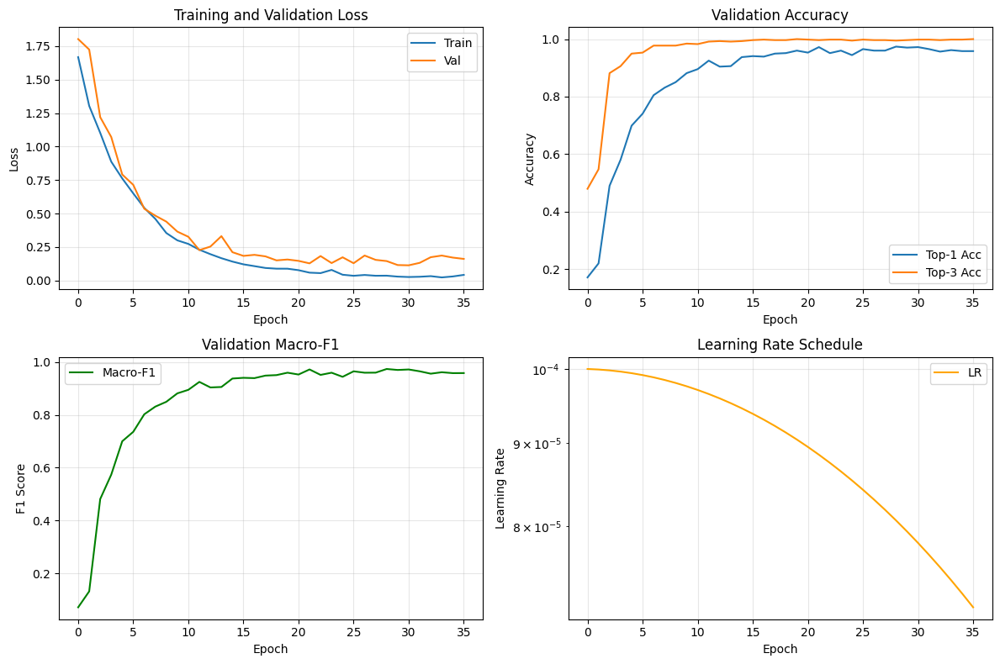

In [12]:
# ===== PLOT TRAINING HISTORY =====
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train')
axes[0, 0].plot(history['val_loss'], label='Val')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history['val_accuracy'], label='Top-1 Acc')
axes[0, 1].plot(history['val_top3_accuracy'], label='Top-3 Acc')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Validation Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# F1 Score
axes[1, 0].plot(history['val_macro_f1'], label='Macro-F1', color='green')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('F1 Score')
axes[1, 0].set_title('Validation Macro-F1')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning Rate
axes[1, 1].plot(history['lr'], label='LR', color='orange')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_title('Learning Rate Schedule')
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_history.png", dpi=150)
plt.show()


---
## 5. Evaluation

Comprehensive evaluation on the held-out test set.


In [13]:
# ===== LOAD BEST MODEL =====
print("Loading best model checkpoint...")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded model from epoch {checkpoint['epoch']} (Val F1: {checkpoint['val_macro_f1']:.4f})")


Loading best model checkpoint...
Loaded model from epoch 29 (Val F1: 0.9738)


In [14]:
# ===== TEST SET EVALUATION =====
model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating on test set"):
        images = images.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)


Evaluating on test set:   0%|          | 0/18 [00:00<?, ?it/s]

In [15]:
# ===== COMPUTE METRICS =====
top1_acc = accuracy_score(all_labels, all_preds)
top3_acc = top_k_accuracy_score(all_labels, all_probs, k=3, labels=range(num_classes)) if num_classes >= 3 else top1_acc
macro_f1 = f1_score(all_labels, all_preds, average='macro')
weighted_f1 = f1_score(all_labels, all_preds, average='weighted')

print("\n" + "=" * 60)
print("TEST SET METRICS")
print("=" * 60)
print(f"Top-1 Accuracy:  {top1_acc:.4f} ({top1_acc*100:.2f}%)")
print(f"Top-3 Accuracy:  {top3_acc:.4f} ({top3_acc*100:.2f}%)")
print(f"Macro F1-Score:  {macro_f1:.4f}")
print(f"Weighted F1:     {weighted_f1:.4f}")
print("=" * 60)



TEST SET METRICS
Top-1 Accuracy:  0.9617 (96.17%)
Top-3 Accuracy:  0.9965 (99.65%)
Macro F1-Score:  0.9616
Weighted F1:     0.9617


In [16]:
# ===== CLASSIFICATION REPORT =====
print("\n=== Per-Class Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))



=== Per-Class Classification Report ===
                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.9479    0.9479    0.9479        96
           Brown Spot     0.9783    0.9278    0.9524        97
    Healthy Rice Leaf     1.0000    1.0000    1.0000        98
           Leaf Blast     0.9216    0.9895    0.9543        95
           Leaf scald     0.9574    0.9574    0.9574        94
        Sheath Blight     0.9677    0.9474    0.9574        95

             accuracy                         0.9617       575
            macro avg     0.9622    0.9617    0.9616       575
         weighted avg     0.9624    0.9617    0.9617       575



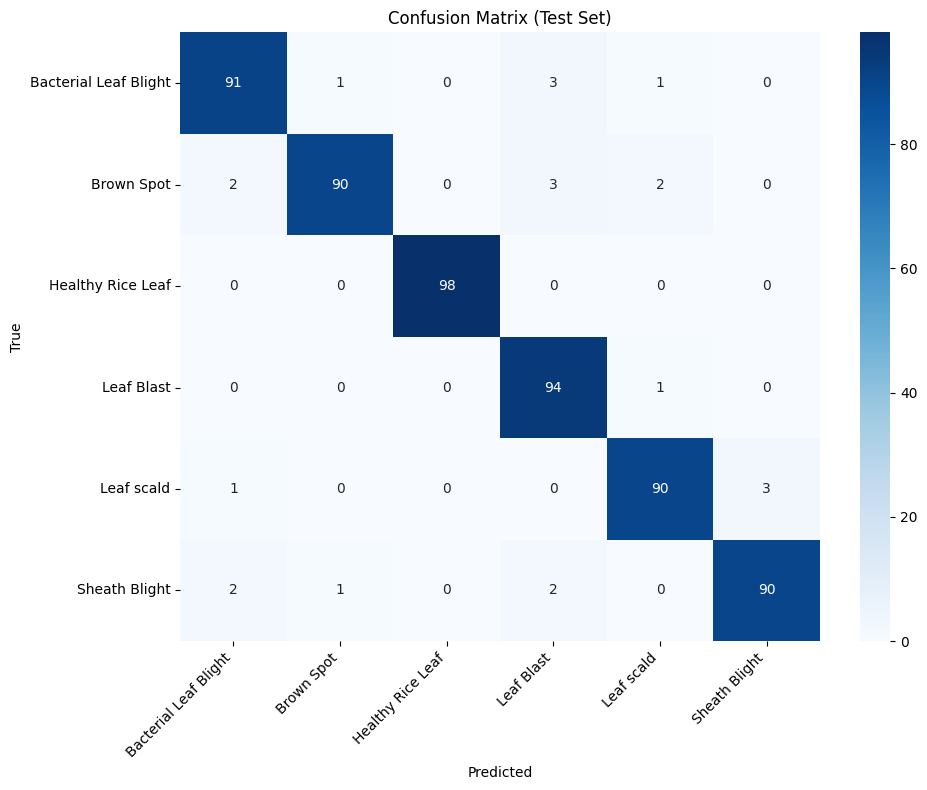

In [17]:
# ===== CONFUSION MATRIX =====
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()


In [18]:
# ===== TOP 5 MOST CONFUSED CLASS PAIRS =====
print("\n=== Top 5 Most Confused Class Pairs ===")

# Find off-diagonal elements (confusion pairs)
confusion_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            confusion_pairs.append((
                class_names[i],  # True class
                class_names[j],  # Predicted class
                cm[i, j]         # Count
            ))

# Sort by confusion count (descending)
confusion_pairs.sort(key=lambda x: x[2], reverse=True)

print(f"{'True Class':<25} {'Predicted As':<25} {'Count':>10}")
print("-" * 65)
for true_cls, pred_cls, count in confusion_pairs[:5]:
    print(f"{true_cls:<25} {pred_cls:<25} {count:>10}")

if not confusion_pairs:
    print("No misclassifications found!")



=== Top 5 Most Confused Class Pairs ===
True Class                Predicted As                   Count
-----------------------------------------------------------------
Bacterial Leaf Blight     Leaf Blast                         3
Brown Spot                Leaf Blast                         3
Leaf scald                Sheath Blight                      3
Brown Spot                Bacterial Leaf Blight              2
Brown Spot                Leaf scald                         2



=== Example Predictions (10 samples with Top-3) ===


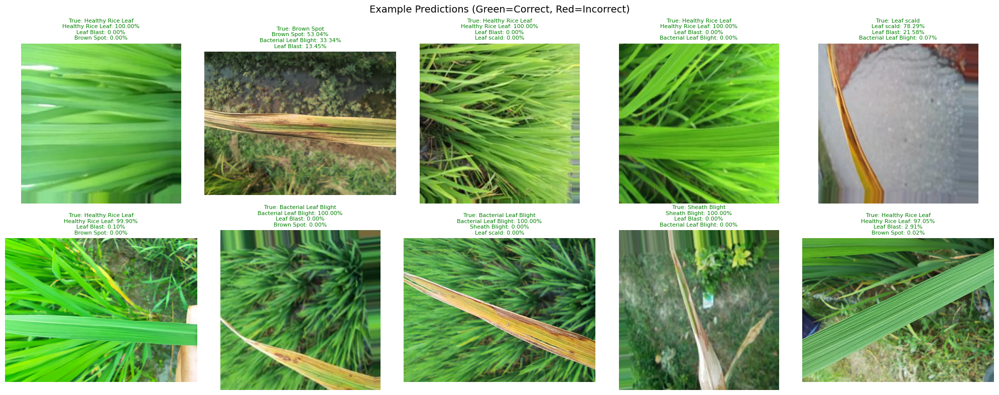

In [19]:
# ===== EXAMPLE PREDICTIONS (10 SAMPLES) =====
print("\n=== Example Predictions (10 samples with Top-3) ===")

# Get sample images and predictions
def get_sample_predictions(dataset, model, device, n_samples=10):
    """Get n sample predictions with original images."""
    model.eval()
    samples = []
    indices = random.sample(range(len(dataset)), min(n_samples, len(dataset)))
    
    for idx in indices:
        if isinstance(dataset, Subset):
            # Get original image (without transforms)
            orig_idx = dataset.indices[idx]
            img_path, true_label = dataset.dataset.samples[orig_idx]
            orig_img = Image.open(img_path).convert('RGB')
            # Apply val transform for model input
            img_tensor = val_test_transform(orig_img).unsqueeze(0).to(device)
        else:
            img_path, true_label = dataset.samples[idx]
            orig_img = Image.open(img_path).convert('RGB')
            img_tensor = val_test_transform(orig_img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(img_tensor)
            probs = F.softmax(output, dim=1)[0]
            top3_probs, top3_idx = probs.topk(min(3, num_classes))
        
        samples.append({
            'image': orig_img,
            'true_label': class_names[true_label],
            'predictions': [
                (class_names[i], p.item()) 
                for i, p in zip(top3_idx.cpu(), top3_probs.cpu())
            ]
        })
    
    return samples

samples = get_sample_predictions(test_dataset, model, device, n_samples=10)

# Display samples
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, (ax, sample) in enumerate(zip(axes.flat, samples)):
    ax.imshow(sample['image'])
    ax.axis('off')
    
    # Build title with predictions
    pred_str = '\n'.join([f"{label}: {prob:.2%}" for label, prob in sample['predictions']])
    is_correct = sample['predictions'][0][0] == sample['true_label']
    color = 'green' if is_correct else 'red'
    
    ax.set_title(f"True: {sample['true_label']}\n{pred_str}", 
                 fontsize=8, color=color)

plt.suptitle('Example Predictions (Green=Correct, Red=Incorrect)', fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/example_predictions.png", dpi=150)
plt.show()


### ROC-AUC Note

**ROC-AUC is skipped for this multi-class classification task.**

Reasons:
1. Multi-class ROC-AUC requires either one-vs-rest (OvR) or one-vs-one (OvO) approaches, 
   which are computationally expensive and less interpretable than Macro-F1 for imbalanced datasets.
2. For our use case (AgriBot keyword hints), precision/recall/F1 per class and top-K accuracy 
   are more actionable metrics.
3. The confusion matrix and per-class F1 scores provide sufficient diagnostic information.


---
## 6. Grad-CAM Explainability

Grad-CAM (Gradient-weighted Class Activation Mapping) visualizes which regions of the input image 
the model focuses on when making predictions. This helps verify that the model attends to 
relevant disease symptoms rather than background artifacts.


In [20]:
# ===== GRAD-CAM IMPLEMENTATION =====
from scipy.ndimage import zoom as scipy_zoom
import cv2

class GradCAM:
    """
    Grad-CAM implementation for MobileNetV3.
    
    Captures gradients and activations from the last convolutional layer
    to generate class-discriminative heatmaps.
    """
    
    def __init__(self, model, target_layer_name='features'):
        self.model = model
        self.gradients = None
        self.activations = None
        
        # Hook the last conv layer in features
        # For MobileNetV3, this is features[-1]
        target_layer = model.backbone.features[-1]
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)
    
    def _save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate_heatmap(self, input_tensor, class_idx=None):
        """
        Generate Grad-CAM heatmap.
        
        Args:
            input_tensor: Input image tensor (1, C, H, W)
            class_idx: Target class index (None = predicted class)
            
        Returns:
            heatmap: Numpy array (H, W) normalized to [0, 1]
            pred_idx: Predicted class index
        """
        self.model.eval()
        input_tensor.requires_grad_(True)
        
        # Forward pass
        output = self.model(input_tensor)
        pred_idx = output.argmax(dim=1).item()
        
        if class_idx is None:
            class_idx = pred_idx
        
        # Backward pass for target class
        self.model.zero_grad()
        output[0, class_idx].backward(retain_graph=True)
        
        # Compute weights (global average pooling of gradients)
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        
        # Weighted combination of activation maps
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)  # Keep positive activations only
        
        # Normalize
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        # Resize to input size
        h, w = input_tensor.shape[2:]
        cam = scipy_zoom(cam, (h / cam.shape[0], w / cam.shape[1]), order=1)
        
        return cam, pred_idx
    
    def visualize(self, image, heatmap, alpha=0.4):
        """
        Overlay heatmap on original image.
        
        Args:
            image: PIL Image or numpy array (H, W, 3)
            heatmap: Grad-CAM heatmap (H, W)
            alpha: Heatmap transparency
            
        Returns:
            overlay: Numpy array (H, W, 3)
        """
        if isinstance(image, Image.Image):
            image = np.array(image)
        
        # Resize heatmap to image size
        heatmap_resized = cv2.resize(heatmap, (image.shape[1], image.shape[0]))
        
        # Apply colormap
        heatmap_colored = cv2.applyColorMap(
            np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET
        )
        heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
        
        # Overlay
        overlay = (1 - alpha) * image + alpha * heatmap_colored
        return np.uint8(np.clip(overlay, 0, 255))


# Create Grad-CAM instance
gradcam = GradCAM(model)
print("Grad-CAM initialized for MobileNetV3")


Grad-CAM initialized for MobileNetV3


In [21]:
# ===== GENERATE GRAD-CAM VISUALIZATIONS =====

def get_correct_incorrect_samples(dataset, model, device, n_each=5):
    """
    Get n correct and n incorrect predictions for Grad-CAM visualization.
    """
    model.eval()
    correct_samples = []
    incorrect_samples = []
    
    # Shuffle indices
    indices = list(range(len(dataset)))
    random.shuffle(indices)
    
    for idx in indices:
        if len(correct_samples) >= n_each and len(incorrect_samples) >= n_each:
            break
            
        if isinstance(dataset, Subset):
            orig_idx = dataset.indices[idx]
            img_path, true_label = dataset.dataset.samples[orig_idx]
        else:
            img_path, true_label = dataset.samples[idx]
        
        orig_img = Image.open(img_path).convert('RGB')
        img_tensor = val_test_transform(orig_img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(img_tensor)
            pred_label = output.argmax(dim=1).item()
            confidence = F.softmax(output, dim=1)[0, pred_label].item()
        
        sample = {
            'image': orig_img,
            'tensor': img_tensor,
            'true_label': true_label,
            'pred_label': pred_label,
            'confidence': confidence
        }
        
        if pred_label == true_label and len(correct_samples) < n_each:
            correct_samples.append(sample)
        elif pred_label != true_label and len(incorrect_samples) < n_each:
            incorrect_samples.append(sample)
    
    return correct_samples, incorrect_samples


print("Collecting samples for Grad-CAM visualization...")
correct_samples, incorrect_samples = get_correct_incorrect_samples(
    test_dataset, model, device, n_each=5
)
print(f"Found {len(correct_samples)} correct and {len(incorrect_samples)} incorrect samples")


Found 5 correct and 5 incorrect samples



=== Grad-CAM: Correct Predictions ===


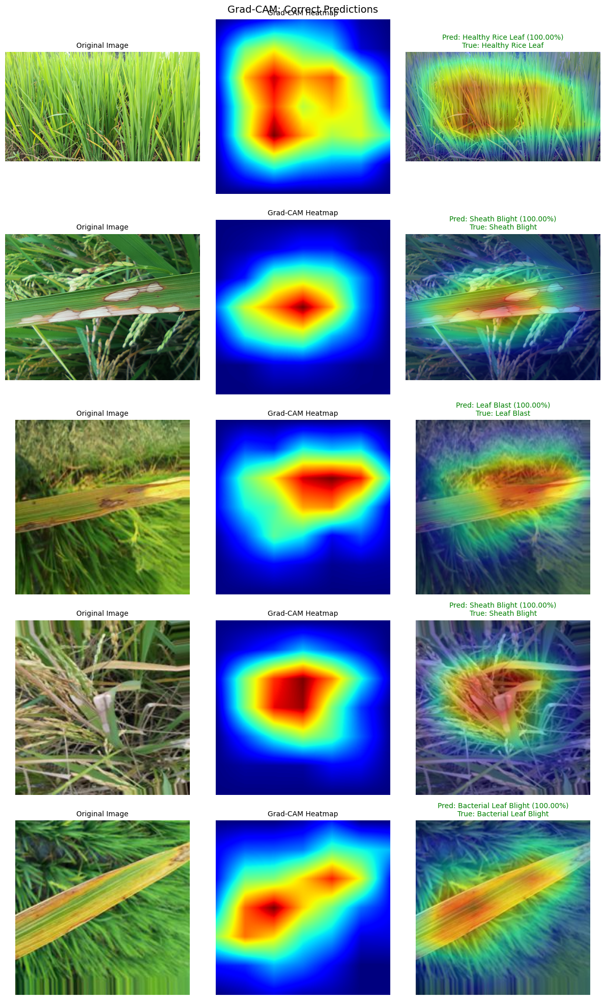

In [22]:
# ===== VISUALIZE CORRECT PREDICTIONS =====
print("\n=== Grad-CAM: Correct Predictions ===")

if correct_samples:
    fig, axes = plt.subplots(len(correct_samples), 3, figsize=(12, 4 * len(correct_samples)))
    if len(correct_samples) == 1:
        axes = axes.reshape(1, -1)

    for i, sample in enumerate(correct_samples):
        img_tensor = sample['tensor'].clone().requires_grad_(True)
        heatmap, _ = gradcam.generate_heatmap(img_tensor)
        overlay = gradcam.visualize(sample['image'], heatmap)
        
        # Original image
        axes[i, 0].imshow(sample['image'])
        axes[i, 0].set_title('Original Image', fontsize=10)
        axes[i, 0].axis('off')
        
        # Heatmap
        axes[i, 1].imshow(heatmap, cmap='jet')
        axes[i, 1].set_title('Grad-CAM Heatmap', fontsize=10)
        axes[i, 1].axis('off')
        
        # Overlay
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title(
            f"Pred: {class_names[sample['pred_label']]} ({sample['confidence']:.2%})\n"
            f"True: {class_names[sample['true_label']]}",
            fontsize=10, color='green'
        )
        axes[i, 2].axis('off')

    plt.suptitle('Grad-CAM: Correct Predictions', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/gradcam_correct.png", dpi=150)
    plt.show()
else:
    print("No correct predictions found for visualization.")



=== Grad-CAM: Incorrect Predictions ===


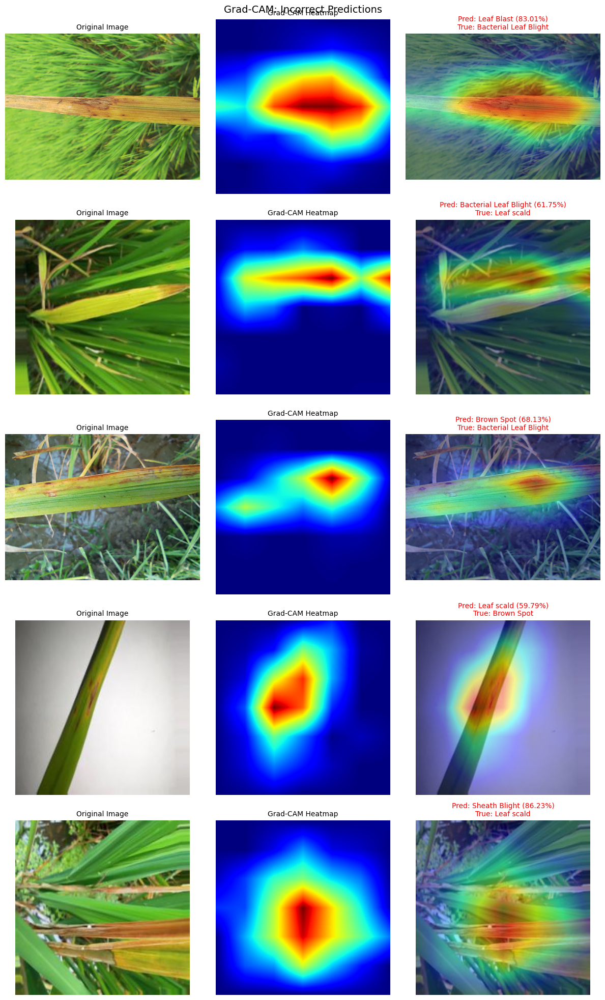

In [23]:
# ===== VISUALIZE INCORRECT PREDICTIONS =====
if incorrect_samples:
    print("\n=== Grad-CAM: Incorrect Predictions ===")
    
    fig, axes = plt.subplots(len(incorrect_samples), 3, figsize=(12, 4 * len(incorrect_samples)))
    if len(incorrect_samples) == 1:
        axes = axes.reshape(1, -1)
    
    for i, sample in enumerate(incorrect_samples):
        img_tensor = sample['tensor'].clone().requires_grad_(True)
        heatmap, _ = gradcam.generate_heatmap(img_tensor)
        overlay = gradcam.visualize(sample['image'], heatmap)
        
        axes[i, 0].imshow(sample['image'])
        axes[i, 0].set_title('Original Image', fontsize=10)
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(heatmap, cmap='jet')
        axes[i, 1].set_title('Grad-CAM Heatmap', fontsize=10)
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title(
            f"Pred: {class_names[sample['pred_label']]} ({sample['confidence']:.2%})\n"
            f"True: {class_names[sample['true_label']]}",
            fontsize=10, color='red'
        )
        axes[i, 2].axis('off')
    
    plt.suptitle('Grad-CAM: Incorrect Predictions', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/gradcam_incorrect.png", dpi=150)
    plt.show()
else:
    print("No incorrect predictions found for Grad-CAM visualization!")


### Grad-CAM Interpretation

**What Grad-CAM Shows:**
- **Hot regions (red/yellow)** indicate areas the model focuses on for its prediction
- **Cold regions (blue)** are largely ignored by the model

**Observations:**
- For correct predictions, the model should ideally focus on disease-affected leaf regions 
  (spots, lesions, discoloration)
- For incorrect predictions, the model may be focusing on:
  - Background elements (soil, sky, other plants)
  - Non-symptomatic regions
  - Image artifacts

**Limitations:**
1. Grad-CAM is **not proof of correctness** - the model may focus on correct regions for wrong reasons
2. **Background bias**: If training images have consistent backgrounds per class, the model may 
   learn spurious correlations
3. Attention may be **distributed** across multiple regions, making interpretation challenging
4. High activation ≠ correct reasoning; domain expert validation is required for deployment


---
## 7. ONNX Export + Validation

Export the trained model to ONNX format for CPU inference in AgriBot.


In [24]:
# ===== INSTALL MISSING DEPENDENCIES =====
# Auto-install onnxscript and onnxruntime if missing
# - onnxscript: required for torch.onnx.export in PyTorch 2.x
# - onnxruntime: required for ONNX model validation and inference

import subprocess
import sys

def _ensure_package(name: str) -> None:
    try:
        __import__(name)
        print(f"  {name} already installed")
    except ImportError:
        print(f"  Installing {name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", name])
        print(f"  {name} installed successfully!")

print("Checking ONNX dependencies...")
_ensure_package("onnxscript")
_ensure_package("onnxruntime")
print("All ONNX dependencies ready.")


Checking ONNX dependencies...
  Installing onnxscript...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 12.3 MB/s eta 0:00:00
  onnxscript installed successfully!
  Installing onnxruntime...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 90.2 MB/s eta 0:00:00
  onnxruntime installed successfully!
All ONNX dependencies ready.


In [25]:
# ===== EXPORT TO ONNX =====
import onnx

model.eval()
model.cpu()  # Export from CPU for compatibility

# Dummy input with dynamic batch
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)

print(f"Exporting model to ONNX: {ONNX_PATH}")

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={
        'input': {0: 'batch_size'},
        'output': {0: 'batch_size'}
    }
)

# Verify ONNX model
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print("✓ ONNX model exported and validated successfully!")
print(f"  File size: {os.path.getsize(ONNX_PATH) / 1024 / 1024:.2f} MB")


Exporting model to ONNX: ./outputs/rice_disease_mobilenetv3_cbam.onnx


W0515 07:12:16.359000 24 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0515 07:12:17.364000 24 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0515 07:12:17.366000 24 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int

[torch.onnx] Obtain model graph for `MobileNetV3CBAM([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3CBAM([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
Runtim

✓ ONNX model exported and validated successfully!
  File size: 0.40 MB


In [26]:
# ===== SAVE LABELS FILE =====
with open(LABELS_PATH, 'w') as f:
    for label in class_names:
        f.write(f"{label}\n")

print(f"Labels saved to: {LABELS_PATH}")
print(f"Labels ({len(class_names)}): {class_names}")


Labels saved to: ./outputs/labels.txt
Labels (6): ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']


In [27]:
# ===== ONNX RUNTIME VALIDATION =====
import onnxruntime as ort

print("\n=== ONNX Runtime Validation ===")

# Create ONNX Runtime session
ort_session = ort.InferenceSession(ONNX_PATH, providers=['CPUExecutionProvider'])
input_name = ort_session.get_inputs()[0].name
output_name = ort_session.get_outputs()[0].name

print(f"Input name: {input_name}")
print(f"Input shape: {ort_session.get_inputs()[0].shape}")
print(f"Output name: {output_name}")
print(f"Output shape: {ort_session.get_outputs()[0].shape}")



=== ONNX Runtime Validation ===
Input name: input
Input shape: ['batch_size', 3, 224, 224]
Output name: output
Output shape: ['batch_size', 6]


In [28]:
# ===== COMPARE PYTORCH vs ONNX PREDICTIONS =====
print("\n=== PyTorch vs ONNX Prediction Comparison ===")

model.to(device)
model.eval()

# Test on 5 images
n_test = 5
indices = random.sample(range(len(test_dataset)), min(n_test, len(test_dataset)))
matches = 0

print(f"{'Sample':<8} {'PyTorch Top-1':<20} {'ONNX Top-1':<20} {'Match':>8}")
print("-" * 60)

for i, idx in enumerate(indices):
    if isinstance(test_dataset, Subset):
        orig_idx = test_dataset.indices[idx]
        img_path, true_label = test_dataset.dataset.samples[orig_idx]
    else:
        img_path, true_label = test_dataset.samples[idx]
    
    # Load and preprocess image
    img = Image.open(img_path).convert('RGB')
    img_tensor = val_test_transform(img).unsqueeze(0)
    
    # PyTorch prediction
    with torch.no_grad():
        pt_output = model(img_tensor.to(device))
        pt_pred = pt_output.argmax(dim=1).item()
    
    # ONNX prediction
    ort_output = ort_session.run([output_name], {input_name: img_tensor.numpy()})[0]
    onnx_pred = ort_output.argmax(axis=1)[0]
    
    # Compare
    match = pt_pred == onnx_pred
    matches += int(match)
    
    print(f"{i+1:<8} {class_names[pt_pred]:<20} {class_names[onnx_pred]:<20} {'✓' if match else '✗':>8}")

print("-" * 60)
print(f"Match rate: {matches}/{n_test} ({matches/n_test:.0%})")



=== PyTorch vs ONNX Prediction Comparison ===
Sample   PyTorch Top-1        ONNX Top-1              Match
------------------------------------------------------------
1        Sheath Blight        Sheath Blight               ✓
2        Leaf Blast           Leaf Blast                  ✓
3        Sheath Blight        Sheath Blight               ✓
4        Leaf Blast           Leaf Blast                  ✓
5        Sheath Blight        Sheath Blight               ✓
------------------------------------------------------------
Match rate: 5/5 (100%)


---
## 8. Inference Helper for AgriBot Integration

The following code snippet can be used to integrate the trained model into AgriBot's 
image classification pipeline.

```python
import numpy as np
import onnxruntime as ort
from PIL import Image
from typing import List, Tuple


# ImageNet normalization constants
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def preprocess(image_path: str, target_size: int = 224) -> np.ndarray:
    """
    Preprocess image for model inference.
    
    Args:
        image_path: Path to image file
        target_size: Target image size (default: 224)
    
    Returns:
        Numpy array of shape (1, 3, H, W) in float32, normalized to ImageNet stats
    """
    # Load and resize
    img = Image.open(image_path).convert('RGB')
    img = img.resize((target_size, target_size), Image.BILINEAR)
    
    # Convert to numpy and normalize
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = (arr - IMAGENET_MEAN) / IMAGENET_STD
    
    # CHW format with batch dimension
    arr = arr.transpose(2, 0, 1)[np.newaxis, ...]
    
    return arr


def softmax(logits: np.ndarray) -> np.ndarray:
    """Compute softmax probabilities."""
    exp_logits = np.exp(logits - logits.max(axis=-1, keepdims=True))
    return exp_logits / exp_logits.sum(axis=-1, keepdims=True)


def predict_top_k(
    session: ort.InferenceSession,
    image_path: str,
    labels: List[str],
    top_k: int = 3,
    confidence_threshold: float = 0.3
) -> List[Tuple[str, float]]:
    """
    Run inference and return Top-K predictions.
    
    Args:
        session: ONNX Runtime InferenceSession
        image_path: Path to input image
        labels: List of class labels (in order)
        top_k: Number of top predictions to return
        confidence_threshold: Minimum confidence to include in results
    
    Returns:
        List of (label, confidence) tuples, sorted by confidence descending.
        Format: [("Brown Spot", 0.85), ("Leaf Blast", 0.12), ...]
        
        This matches AgriBot's expected format:
        List[PossibleCondition(label, confidence)]
    """
    # Preprocess
    input_tensor = preprocess(image_path)
    
    # Run inference
    input_name = session.get_inputs()[0].name
    outputs = session.run(None, {input_name: input_tensor})
    logits = outputs[0][0]
    
    # Softmax
    probs = softmax(logits)
    
    # Get Top-K
    top_indices = probs.argsort()[::-1][:top_k]
    
    results = []
    for idx in top_indices:
        conf = float(probs[idx])
        if conf >= confidence_threshold:
            results.append((labels[idx], conf))
    
    return results


# ===== USAGE EXAMPLE =====
# model_path = "outputs/rice_disease_mobilenetv3_cbam.onnx"
# labels_path = "outputs/labels.txt"
# 
# # Load labels
# with open(labels_path, 'r') as f:
#     labels = [line.strip() for line in f if line.strip()]
# 
# # Create session
# session = ort.InferenceSession(model_path, providers=['CPUExecutionProvider'])
# 
# # Predict
# results = predict_top_k(session, "test_image.jpg", labels, top_k=3)
# for label, conf in results:
#     print(f"{label}: {conf:.2%}")
```


### Low-Confidence / Unknown Handling Policy

Since the model may not include a "Healthy" class or may encounter out-of-distribution images, 
implement the following policy in AgriBot integration:

```python
CONFIDENCE_THRESHOLD = 0.3  # Minimum confidence for any prediction
UNKNOWN_THRESHOLD = 0.5     # Below this, flag as "Needs Expert Review"

def get_classification_with_safety(predictions: List[Tuple[str, float]]) -> dict:
    """
    Apply safety policy to classification results.
    
    Returns:
        {
            'predictions': [(label, conf), ...],
            'confidence_level': 'high' | 'medium' | 'low',
            'needs_expert_review': bool,
            'warning': str or None
        }
    """
    if not predictions:
        return {
            'predictions': [],
            'confidence_level': 'low',
            'needs_expert_review': True,
            'warning': 'No confident predictions. Please consult an agricultural expert.'
        }
    
    top_conf = predictions[0][1]
    
    if top_conf >= 0.7:
        level = 'high'
        needs_review = False
        warning = None
    elif top_conf >= UNKNOWN_THRESHOLD:
        level = 'medium'
        needs_review = False
        warning = 'Moderate confidence. Consider visual inspection by expert.'
    else:
        level = 'low'
        needs_review = True
        warning = 'Low confidence prediction. Expert consultation recommended.'
    
    return {
        'predictions': predictions,
        'confidence_level': level,
        'needs_expert_review': needs_review,
        'warning': warning
    }
```


---
## 9. Model Card / Summary

### Rice Disease Image Classifier v1.0

#### Model Description
- **Architecture**: MobileNetV3-Large + CBAM (Convolutional Block Attention Module)
- **Task**: Multi-class rice disease classification
- **Input**: RGB images, 224×224 pixels, ImageNet-normalized
- **Output**: Class probabilities (softmax)
- **Framework**: PyTorch → ONNX (opset 12)
- **Inference**: CPU-optimized via ONNX Runtime

#### Dataset
- **Source**: [Update with your dataset source]
- **Classes**: [Listed in labels.txt]
- **Split**: 70% train / 15% val / 15% test (stratified)
- **Preprocessing**: RandomResizedCrop, horizontal flip, rotation, color jitter

#### Performance Metrics (Test Set)
| Metric | Value |
|--------|-------|
| Top-1 Accuracy | [See evaluation above] |
| Top-3 Accuracy | [See evaluation above] |
| Macro F1-Score | [See evaluation above] |
| Weighted F1 | [See evaluation above] |

#### Intended Use
- **Primary Use**: Generate keyword hints for RAG-based agricultural advice system (AgriBot)
- **NOT for**: Final diagnosis or treatment decisions
- **Input Requirement**: Clear, well-lit photos of rice leaves/plants

#### Limitations & Risks
1. **Not a diagnostic tool**: Predictions are hints for information retrieval, not medical/agricultural diagnoses
2. **Domain shift**: Performance may degrade on images from different:
   - Geographic regions
   - Camera types
   - Lighting conditions
   - Rice varieties
3. **No "Healthy" class**: If absent in training data, model cannot confirm healthy plants
4. **Class confusion**: See confusion matrix for known error patterns
5. **Background bias**: Model may learn spurious correlations from training backgrounds

#### Ethical Considerations
- Always present results with confidence levels and disclaimers
- Encourage expert consultation for treatment decisions
- Do not use predictions as sole basis for pesticide/fungicide application

#### Maintenance
- **Version**: 1.0
- **Last Updated**: [Date]
- **Retraining**: Recommended when accuracy drops below 80% on new test samples


In [29]:
# ===== FINAL SUMMARY =====
print("\n" + "=" * 80)
print("TRAINING AND EXPORT COMPLETE")
print("=" * 80)
print("\nOutput Artifacts:")
print(f"  • PyTorch checkpoint: {CHECKPOINT_PATH}")
print(f"  • ONNX model:         {ONNX_PATH}")
print(f"  • Labels file:        {LABELS_PATH}")
print(f"  • Training history:   {OUTPUT_DIR}/training_history.png")
print(f"  • Confusion matrix:   {OUTPUT_DIR}/confusion_matrix.png")
print(f"  • Grad-CAM images:    {OUTPUT_DIR}/gradcam_*.png")
print("\nModel Configuration:")
print("  • Backbone: MobileNetV3-Large")
print(f"  • CBAM: {'Enabled' if USE_CBAM else 'Disabled'}")
print(f"  • Classes: {num_classes}")
print("\nTest Set Performance:")
print(f"  • Top-1 Accuracy: {top1_acc:.4f}")
print(f"  • Top-3 Accuracy: {top3_acc:.4f}")
print(f"  • Macro F1-Score: {macro_f1:.4f}")
print("\n" + "=" * 80)



TRAINING AND EXPORT COMPLETE

Output Artifacts:
  • PyTorch checkpoint: ./outputs/rice_disease_best.pt
  • ONNX model:         ./outputs/rice_disease_mobilenetv3_cbam.onnx
  • Labels file:        ./outputs/labels.txt
  • Training history:   ./outputs/training_history.png
  • Confusion matrix:   ./outputs/confusion_matrix.png
  • Grad-CAM images:    ./outputs/gradcam_*.png

Model Configuration:
  • Backbone: MobileNetV3-Large
  • CBAM: Enabled
  • Classes: 6

Test Set Performance:
  • Top-1 Accuracy: 0.9617
  • Top-3 Accuracy: 0.9965
  • Macro F1-Score: 0.9616

